In [118]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [119]:
def convert_8bit_plane(Im):
    bit = 1
    n,m = Im.shape[0], Im.shape[1]
    res = []
    for bit in range(8):
        new_image = Im.copy()
        for i in range(n):
            for j in range(m): 
                xx = Im[i][j]
                if xx & (1 << bit):
                    new_image[i][j] = 255
                else:
                    new_image[i][j] = 0
        res.append(new_image)
    return res

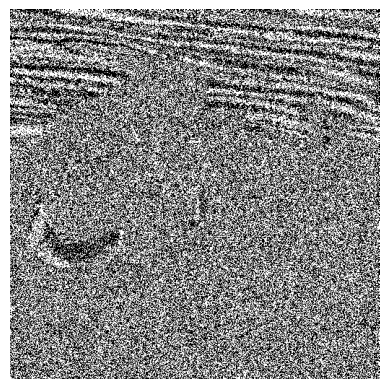

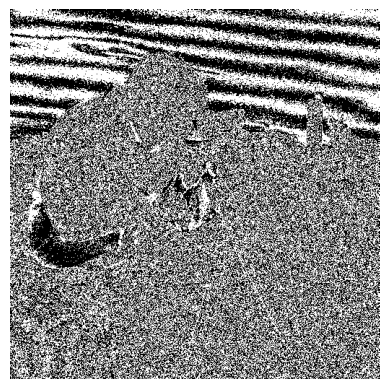

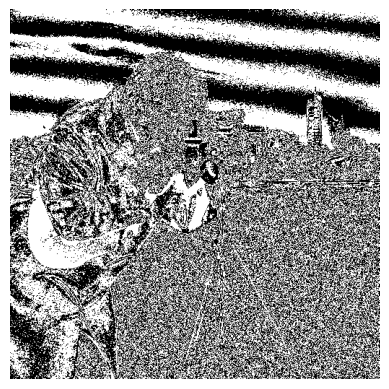

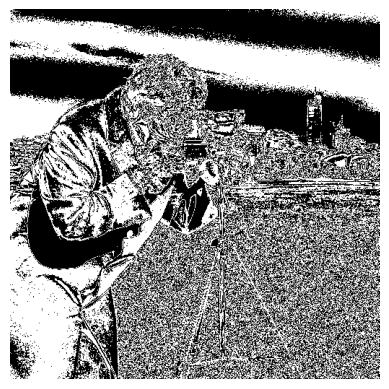

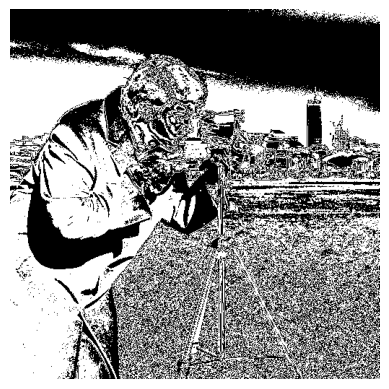

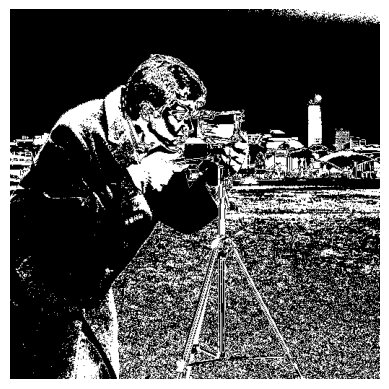

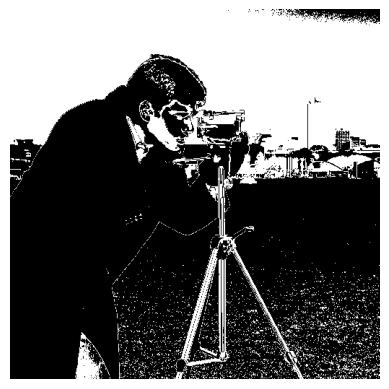

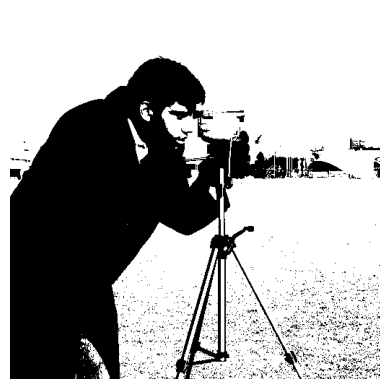

In [120]:
img = cv2.imread("Cameraman.png", cv2.IMREAD_GRAYSCALE)
res = convert_8bit_plane(img)
for new_image in res:
    plt.imshow(new_image, cmap='gray')
    plt.axis("off")
    plt.show()

In [121]:
def mean_filter(Im, k):
    n,m = Im.shape[0], Im.shape[1]
    p = k // 2
    new_image = np.zeros((n,m), dtype=np.uint8)
    Img = np.pad(Im.copy(), p, 'edge')
    for i in range (p, n-p):
        for j in range (p, m-p):
            total = 0.0
            for x in range(-p, p):
                for y in range(-p, p):
                    total += Img[i+x][j+y]
            mean =  total // (k*k)
            # print(mean)
            new_image[i-p][j-p] = mean

    return new_image

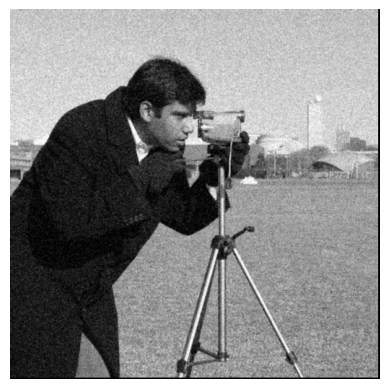

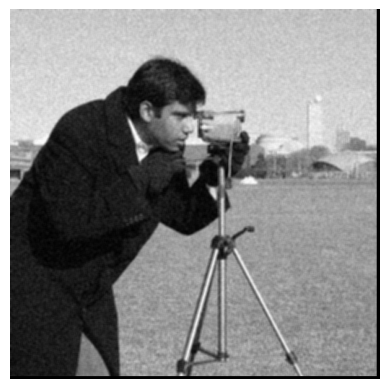

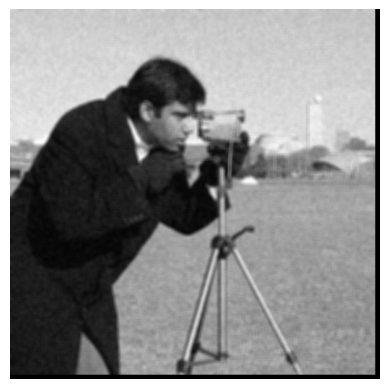

In [122]:
img1 = cv2.imread("Gaussian_Noisy_Image.png", cv2.IMREAD_GRAYSCALE)

for k in [3,5,7]:
    res = mean_filter(img1, k)
    
    plt.imshow(res, cmap='gray')
    plt.axis("off")
    plt.show()

In [ ]:
def median_filter(Im, k):
    n,m = Im.shape[0], Im.shape[1]
    p = k // 2
    new_image = np.zeros((n,m), dtype=np.uint8)
    Img = np.pad(Im.copy(), p)
    for i in range (p, n-p):
        for j in range (p, m-p):
            neighbour = []
            for x in range(-p, p+1):
                for y in range(-p, p+1):
                    neighbour.append(Img[i+x][j+y])
            # median = np.median(neighbour)
            neighbour.sort()
            # print(len(neighbour))
            median = neighbour[((k*k)//2)]
            new_image[i-p][j-p] = median

    return new_image

def mse(original, filtered):
    n,m = original.shape
    total = 0.0

    for i in range(n):
        for j in range(m):
            diff = original[i][j] - filtered[i][j]
            total += (diff * diff)

    return total // (n*m)

def psnr(original, filtered):
    n,m = original.shape
    total = 0.0
    mseval = mse(original, filtered)
    if(mseval == 0):
        return

    max_i = 255

    ans = 10* np.log10((max_i* max_i)/mseval)
    return ans

In [ ]:
img2 = cv2.imread("Salt_Pepper_Noisy_Image.png", cv2.IMREAD_GRAYSCALE)
mean_filtered = mean_filter(img2, 3)
median_filtered = median_filter(img2, 3)

print("mean MSE: ", mse(img2, mean_filtered))
print("mean PSNR: ", psnr(img2, mean_filtered))

print("median MSE: ", mse(img2, median_filtered))
print("median PSNR: ", psnr(img2, median_filtered))

9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9
9


C:\Users\students\AppData\Local\Temp\ipykernel_14948\2340958113.py:27: RuntimeWarning: overflow encountered in scalar multiply
  total += (diff * diff)
C:\Users\students\AppData\Local\Temp\ipykernel_14948\2340958113.py:26: RuntimeWarning: overflow encountered in scalar subtract
  diff = original[i][j] - filtered[i][j]


mean MSE:  108.0
